# Análise exploratória — Parte 2 (Starved Lubrication)

Perguntas: estrutura e qualidade dos dados · o que muda no espectro entre `fit` e `predict` · quais features separam as classes
(absoluto vs relativo ao `fit`) · quantos sinais de um starved mostram o sintoma · o teste se parece com o treino?

In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as sps, stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "part2"

# Paleta (validada para daltonismo): healthy = azul, starved = laranja, sem rótulo = cinza
C = {"healthy": "#2a78d6", "starved": "#eb6834", "unlabeled": "#8a8a85", "test": "#8a8a85"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "lines.linewidth": 1.6,
})
pd.set_option("display.width", 140, "display.max_columns", 30)

## 1. Imports e steup inicial

In [27]:
labels = pd.read_csv(DATA / "labels.csv")
labels["starved"] = labels["label"].str.contains("starved")
print("Rótulos originais:", labels.label.value_counts().to_dict())
lab_map = dict(zip(labels.asset_id, np.where(labels.starved, "starved", "healthy")))

rows = []
for split in ["assets", "test_data"]:
    for d in sorted(p for p in (DATA / split).iterdir() if p.is_dir()):
        for s in ["fit", "predict"]:
            z = np.load(d / f"{s}.npz")
            rows.append(dict(split=split, asset_id=d.name, set=s, n=z["data"].shape[0], L=z["data"].shape[1],
                             dtype=str(z["data"].dtype), fs=float(np.round(1 / z["dt"][0], 1)),
                             n_fs=np.unique(z["dt"]).size))
inv = pd.DataFrame(rows)
inv["label"] = inv.asset_id.map(lab_map).fillna(
    pd.Series(np.where(inv.split == "test_data", "test", "unlabeled"), index=inv.index))

print("Assets por split/rótulo:")
print(inv.drop_duplicates("asset_id").groupby(["split", "label"]).size().to_string(), "\n")
print("Sinais por conjunto (n) — valores distintos:", inv.groupby("set").n.unique().to_dict())
print("Comprimento L:", inv.L.unique(), "| dtype:", inv.dtype.unique())
print("dt único dentro de cada arquivo:", (inv.n_fs == 1).all())
print("Rótulos sem pasta:", set(labels.asset_id) - set(inv.asset_id))
print("Assets sem rótulo em assets/:", sorted(inv[(inv.split == 'assets') & (inv.label == 'unlabeled')].asset_id.unique()))

Rótulos originais: {'healthy': 96, 'starved lubrication': 48}
Assets por split/rótulo:
split      label    
assets     healthy      96
           starved      48
           unlabeled     2
test_data  test         20 

Sinais por conjunto (n) — valores distintos: {'fit': array([60, 86, 68]), 'predict': array([30, 39, 48])}
Comprimento L: [32000] | dtype: <StringArray>
['float16']
Length: 1, dtype: str
dt único dentro de cada arquivo: False
Rótulos sem pasta: set()
Assets sem rótulo em assets/: ['test 6864339ebf3fa7dcb33fd51b', 'test 689e4e90dc68b26704d071d6']


fs igual entre fit e predict no mesmo asset: 0.988


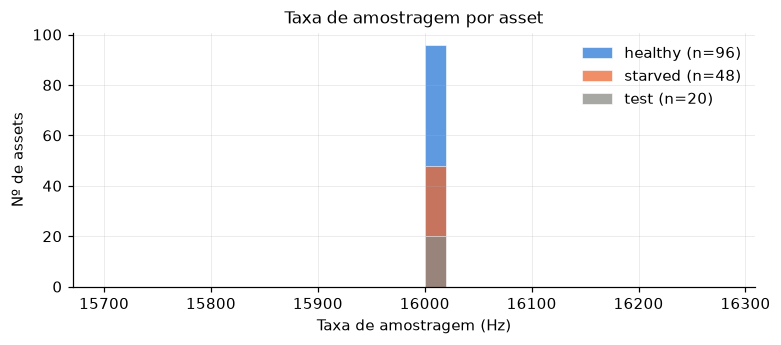

In [28]:
fs_asset = inv.pivot_table(index=["asset_id", "label"], columns="set", values="fs").reset_index()
print("fs igual entre fit e predict no mesmo asset:", (fs_asset.fit == fs_asset.predict).mean().round(3))

fig, ax = plt.subplots(figsize=(8, 3))
bins = np.arange(15700, 16300, 20)
for lab in ["healthy", "starved", "test"]:
    v = fs_asset[fs_asset.label.str.startswith(lab[:4])].fit if lab != "test" else fs_asset[fs_asset.label == "test"].fit
    ax.hist(v, bins=bins, color=C[lab], alpha=0.75, label=f"{lab} (n={len(v)})", edgecolor="white", linewidth=0.5)
ax.set(xlabel="Taxa de amostragem (Hz)", ylabel="Nº de assets", title="Taxa de amostragem por asset")
ax.legend(); plt.show()

Leitura: 60 sinais de `fit` e 30 de `predict` por asset, 32 000 amostras a ~16 kHz em `float16` (converter para `float32` antes de somar quadrados).

## 2. Processamento por sinal (PSD + features)

### Qualidade dos sinais

Checagem de valores inválidos (NaN/inf) e de saturação. `clip_frac` é a fração de amostras com |x| ≥ 99,9% do
máximo do sinal: num sinal saturado, muitas amostras ficam "grudadas" no teto; num sinal normal, só o pico chega lá.

In [29]:
FMAX = 7800.0                      # abaixo do Nyquist do menor fs
FGRID = np.arange(0, FMAX + 1, 8.0)
NPERSEG = 2048
BANDS = [(0, 500), (500, 1000), (1000, 2000), (2000, 3000), (3000, 4000),
         (4000, 5000), (5000, 6000), (6000, 7000), (7000, 7800)]

def signal_features(x, fs):
    x = x - x.mean()
    rms = np.sqrt(np.mean(x ** 2))
    f, P = sps.welch(x, fs=fs, nperseg=NPERSEG)
    df = f[1] - f[0]
    feat = dict(rms=rms, crest=np.max(np.abs(x)) / rms, kurt=stats.kurtosis(x, fisher=False),
                skew=stats.skew(x), clip_frac=np.mean(np.abs(x) >= 0.999 * np.max(np.abs(x))))
    for lo, hi in BANDS:
        m = (f >= lo) & (f < hi)
        feat[f"logE_{lo}_{hi}"] = np.log10(P[m].sum() * df + 1e-12)
    hf = (f >= 1000) & (f <= FMAX)
    Ph = P[hf]
    feat["centroid_hf"] = (f[hf] * Ph).sum() / Ph.sum()
    feat["flatness_hf"] = np.exp(np.mean(np.log(Ph + 1e-20))) / np.mean(Ph)
    p = Ph / Ph.sum()
    feat["entropy_hf"] = -(p * np.log(p + 1e-20)).sum() / np.log(len(p))
    return feat, np.interp(FGRID, f, P)

feat_rows, psd_rows = [], []
for d in sorted(inv.drop_duplicates("asset_id").itertuples(), key=lambda r: r.asset_id):
    for s in ["fit", "predict"]:
        z = np.load(DATA / d.split / d.asset_id / f"{s}.npz")
        X = z["data"].astype(np.float32)
        for i, (x, dt, sid) in enumerate(zip(X, z["dt"], z["sample_ids"])):
            ft, P = signal_features(x, 1 / dt)
            ft.update(asset_id=d.asset_id, split=d.split, label=d.label, set=s, idx=i,
                      sample_id=str(sid), finite=bool(np.isfinite(x).all()))
            feat_rows.append(ft); psd_rows.append(P)

F = pd.DataFrame(feat_rows)
PSD = np.log10(np.vstack(psd_rows) + 1e-14)          # log-PSD na grade comum
# Toda chave nova devolvida por signal_features (ex.: features novas) entra automaticamente em FEATS
META_COLS = {"asset_id", "split", "label", "set", "idx", "sample_id", "finite", "clip_frac"}
FEATS = [c for c in F.columns if c not in META_COLS]
print(F.shape, "| features:", len(FEATS))
print("Sinais com NaN/inf:", (~F.finite).sum(), "| sinais com possível clipping (>0,1% amostras no pico):",
      (F.clip_frac > 1e-3).sum())

(15001, 24) | features: 16
Sinais com NaN/inf: 0 | sinais com possível clipping (>0,1% amostras no pico): 0


## 3. Como são os sinais

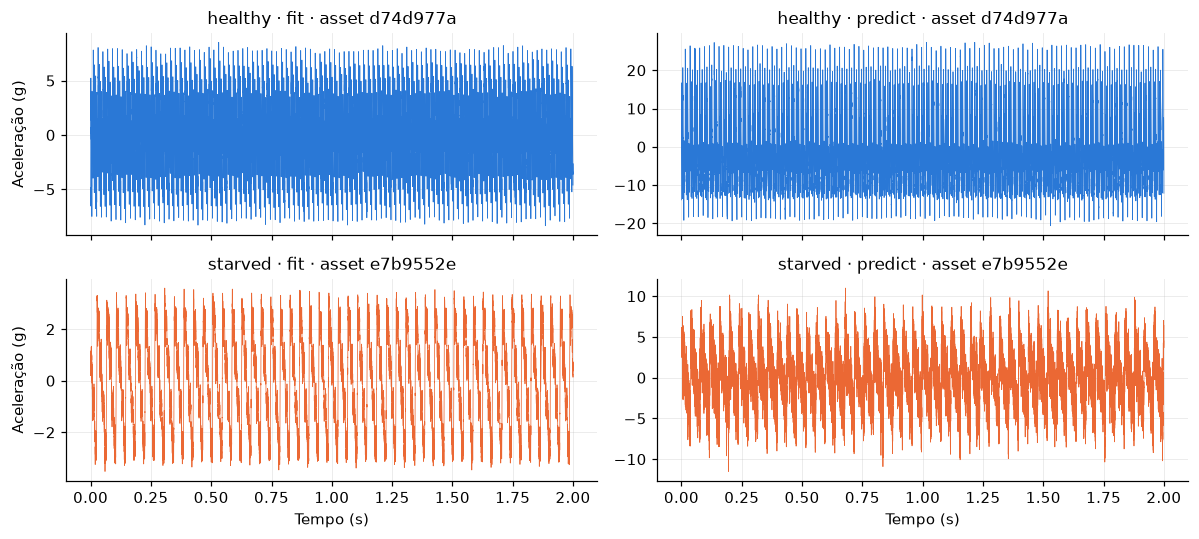

In [30]:
def pick(label, k=1, seed=0):
    ids = F[F.label == label].asset_id.unique()
    return list(np.random.default_rng(seed).choice(ids, k, replace=False))

ex = {"healthy": pick("healthy")[0], "starved": pick("starved")[0]}
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex=True)
for r, (lab, aid) in enumerate(ex.items()):
    split = F[F.asset_id == aid].split.iloc[0]
    for c, s in enumerate(["fit", "predict"]):
        z = np.load(DATA / split / aid / f"{s}.npz")
        x = z["data"][0].astype(np.float32); x -= x.mean()
        t = np.arange(len(x)) * z["dt"][0]
        axes[r, c].plot(t, x, color=C[lab], linewidth=0.5)
        axes[r, c].set_title(f"{lab} · {s} · asset {aid[:8]}")
axes[1, 0].set_xlabel("Tempo (s)"); axes[1, 1].set_xlabel("Tempo (s)")
axes[0, 0].set_ylabel("Aceleração (g)"); axes[1, 0].set_ylabel("Aceleração (g)")
plt.tight_layout(); plt.show()

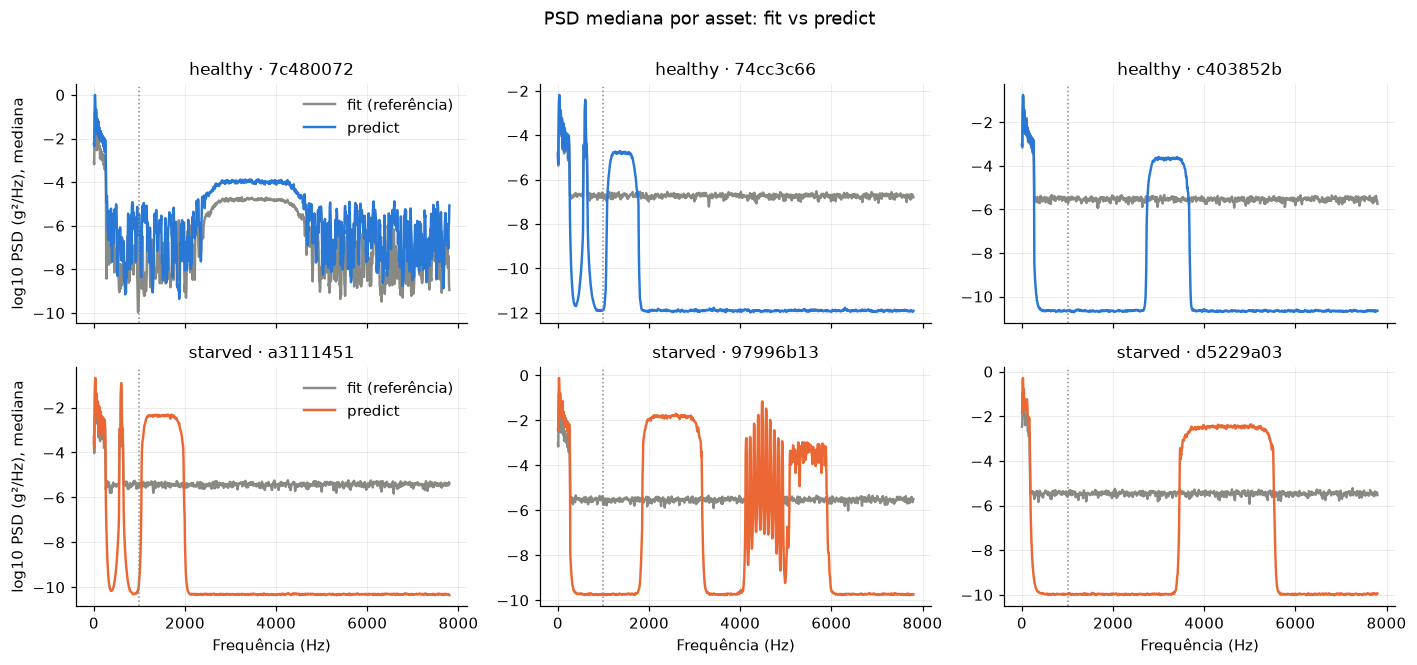

In [31]:
def asset_psd(aid, s):
    m = ((F.asset_id == aid) & (F.set == s)).values
    return np.median(PSD[m], axis=0)

ids = {"healthy": pick("healthy", 3, 1), "starved": pick("starved", 3, 1)}
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for r, lab in enumerate(ids):
    for c, aid in enumerate(ids[lab]):
        ax = axes[r, c]
        ax.plot(FGRID, asset_psd(aid, "fit"), color="#8a8a85", label="fit (referência)")
        ax.plot(FGRID, asset_psd(aid, "predict"), color=C[lab], label="predict")
        ax.axvline(1000, color="#8a8a85", linestyle=":", linewidth=1)
        ax.set_title(f"{lab} · {aid[:8]}")
        if c == 0: ax.set_ylabel("log10 PSD (g²/Hz), mediana")
        if r == 1: ax.set_xlabel("Frequência (Hz)")
axes[0, 0].legend(); axes[1, 0].legend()
plt.suptitle("PSD mediana por asset: fit vs predict", y=1.0); plt.tight_layout(); plt.show()

## 4. Assinatura espectral por classe: Δ log-PSD (predict − fit)

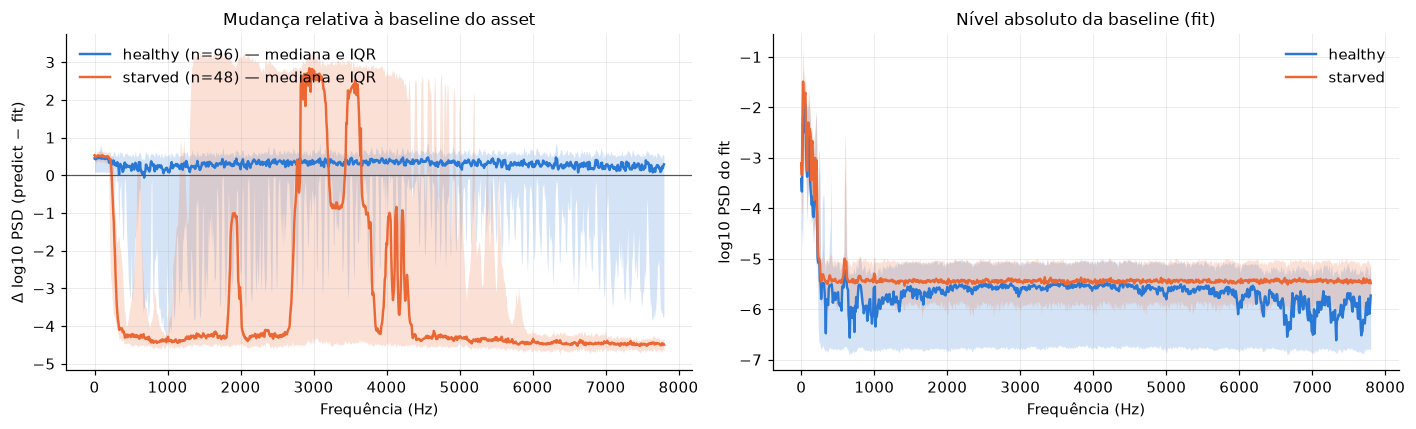

In [32]:
lab_assets = F[F.split == "assets"].drop_duplicates("asset_id")[["asset_id", "label"]]
lab_assets = lab_assets[lab_assets.label.isin(["healthy", "starved"])].sort_values(["label", "asset_id"])
DELTA = np.vstack([asset_psd(a, "predict") - asset_psd(a, "fit") for a in lab_assets.asset_id])
BASE = np.vstack([asset_psd(a, "fit") for a in lab_assets.asset_id])
y = (lab_assets.label == "starved").values

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for lab, m in [("healthy", ~y), ("starved", y)]:
    q25, q50, q75 = np.percentile(DELTA[m], [25, 50, 75], axis=0)
    axes[0].fill_between(FGRID, q25, q75, color=C[lab], alpha=0.2, linewidth=0)
    axes[0].plot(FGRID, q50, color=C[lab], label=f"{lab} (n={m.sum()}) — mediana e IQR")
    b25, b50, b75 = np.percentile(BASE[m], [25, 50, 75], axis=0)
    axes[1].fill_between(FGRID, b25, b75, color=C[lab], alpha=0.2, linewidth=0)
    axes[1].plot(FGRID, b50, color=C[lab], label=lab)
axes[0].axhline(0, color="#555", linewidth=0.8)
axes[0].set(xlabel="Frequência (Hz)", ylabel="Δ log10 PSD (predict − fit)", title="Mudança relativa à baseline do asset")
axes[1].set(xlabel="Frequência (Hz)", ylabel="log10 PSD do fit", title="Nível absoluto da baseline (fit)")
axes[0].legend(loc="upper left"); axes[1].legend()
plt.tight_layout(); plt.show()

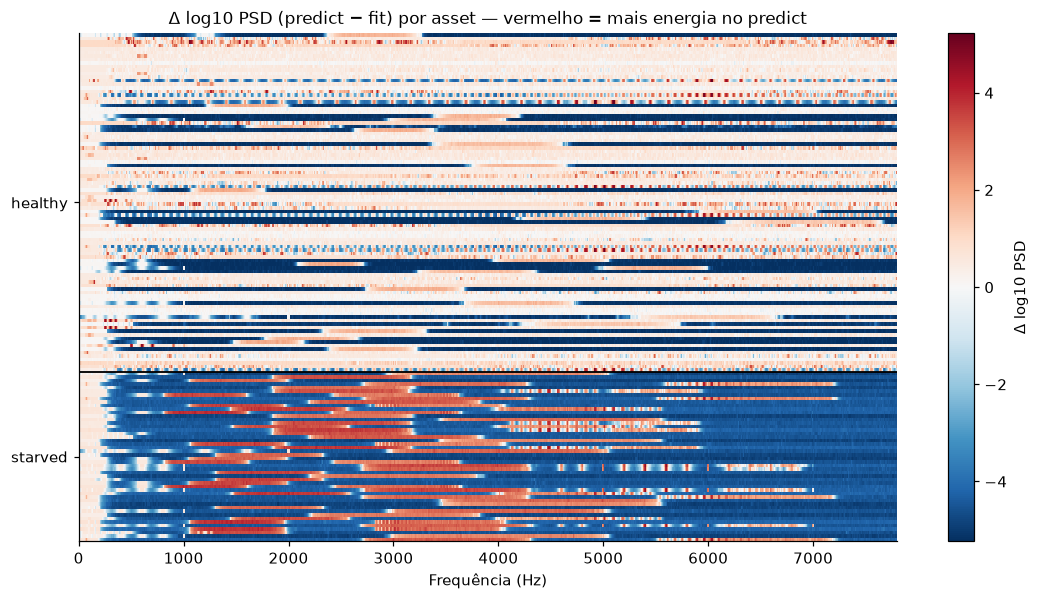

In [33]:
lim = np.percentile(np.abs(DELTA), 98)
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(DELTA, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim,
               extent=[FGRID[0], FGRID[-1], len(DELTA), 0], interpolation="nearest")
ax.axhline((~y).sum(), color="black", linewidth=1.2)
ax.set_yticks([(~y).sum() / 2, (~y).sum() + y.sum() / 2]); ax.set_yticklabels(["healthy", "starved"])
ax.set(xlabel="Frequência (Hz)", title="Δ log10 PSD (predict − fit) por asset — vermelho = mais energia no predict")
plt.colorbar(im, ax=ax, label="Δ log10 PSD"); ax.grid(False); plt.show()

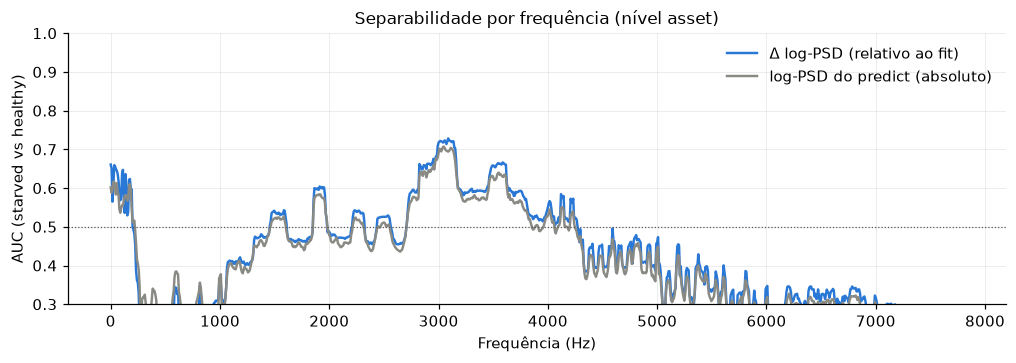

AUC máx. relativo: 0.728 em 3088 Hz | AUC máx. absoluto: 0.707 em 3048 Hz


In [34]:
# Separabilidade por frequência: AUC de Δ log-PSD em cada bin (asset-level)
def auc(score, yb):
    score, yb = np.asarray(score, float), np.asarray(yb, bool)
    u = stats.mannwhitneyu(score[yb], score[~yb]).statistic
    return u / (yb.sum() * (~yb).sum())

auc_f = np.array([auc(DELTA[:, j], y) for j in range(DELTA.shape[1])])
auc_abs = np.array([auc(BASE[:, j] + DELTA[:, j], y) for j in range(DELTA.shape[1])])  # predict absoluto
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(FGRID, auc_f, color="#2a78d6", label="Δ log-PSD (relativo ao fit)")
ax.plot(FGRID, auc_abs, color="#8a8a85", label="log-PSD do predict (absoluto)")
ax.axhline(0.5, color="#555", linewidth=0.8, linestyle=":")
ax.set(xlabel="Frequência (Hz)", ylabel="AUC (starved vs healthy)", ylim=(0.3, 1.0),
       title="Separabilidade por frequência (nível asset)")
ax.legend(); plt.show()
print("AUC máx. relativo: %.3f em %.0f Hz | AUC máx. absoluto: %.3f em %.0f Hz"
      % (auc_f.max(), FGRID[auc_f.argmax()], auc_abs.max(), FGRID[auc_abs.argmax()]))

## 5. Features: absoluto vs relativo à baseline

In [35]:
def robust_z(df):
    ref = df[df.set == "fit"][FEATS]
    med = ref.median()
    mad = 1.4826 * (ref - med).abs().median()
    scale = mad.where(mad > 1e-9, ref.std() + 1e-9)
    return (df[FEATS] - med) / scale

Z = F.groupby("asset_id", group_keys=False).apply(robust_z)
Z = pd.concat([F[["asset_id", "split", "label", "set", "idx"]], Z], axis=1)

P_abs = F[F.set == "predict"].groupby("asset_id")[FEATS].median()
P_z75 = Z[Z.set == "predict"].groupby("asset_id")[FEATS].quantile(0.75)
P_zmed = Z[Z.set == "predict"].groupby("asset_id")[FEATS].median()
meta = F.drop_duplicates("asset_id").set_index("asset_id")[["split", "label"]]
lab_idx = meta[meta.label.isin(["healthy", "starved"])].index
yy = (meta.loc[lab_idx, "label"] == "starved").values

tab = pd.DataFrame({
    "AUC absoluto (mediana predict)": [auc(P_abs.loc[lab_idx, f], yy) for f in FEATS],
    "AUC relativo (mediana z)": [auc(P_zmed.loc[lab_idx, f], yy) for f in FEATS],
    "AUC relativo (p75 z)": [auc(P_z75.loc[lab_idx, f], yy) for f in FEATS],
}, index=FEATS)
tab["melhor |AUC−0,5|"] = (tab - 0.5).abs().max(axis=1) + 0.5
tab = tab.sort_values("melhor |AUC−0,5|", ascending=False)
tab.round(3)

,AUC absoluto (mediana predict),AUC relativo (mediana z),AUC relativo (p75 z),"melhor |AUC−0,5|"
crest,0.931,0.939,0.941,0.941
kurt,0.874,0.889,0.827,0.889
flatness_hf,0.129,0.184,0.170,0.871
logE_7000_7800,0.203,0.176,0.142,0.858
logE_6000_7000,0.234,0.227,0.161,0.839
logE_3000_4000,0.757,0.794,0.811,0.811
logE_2000_3000,0.753,0.790,0.795,0.795
logE_1000_2000,0.676,0.730,0.719,0.730
skew,0.463,0.460,0.273,0.727
rms,0.635,0.713,0.714,0.714


AUC > 0,5 significa "maior em starved"; AUC < 0,5 significa "menor em starved" (o módulo da distância a 0,5 é o que importa).
A AUC é calculada com um valor por asset (144 assets rotulados), que é o tamanho amostral honesto.

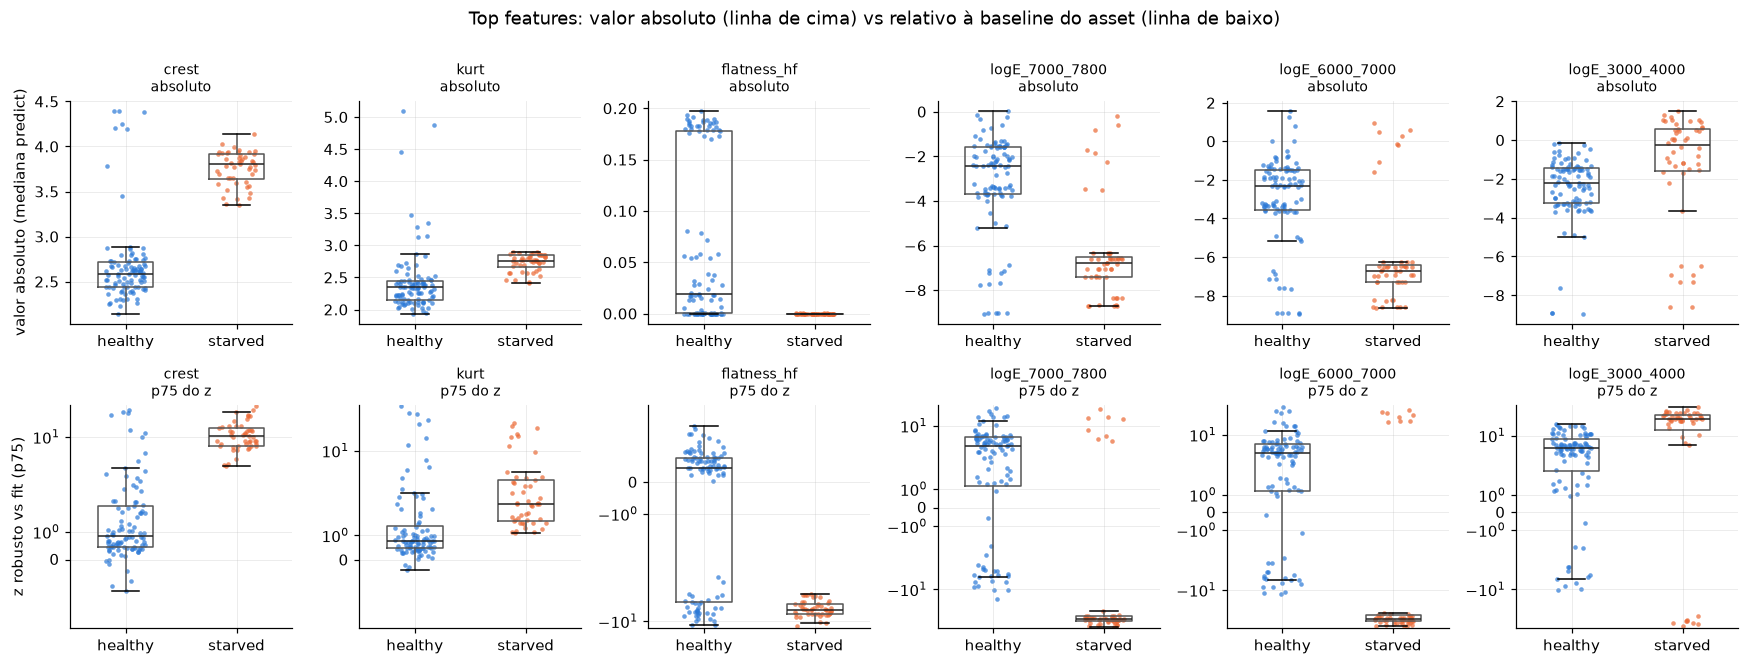

In [36]:
top = list(tab.index[:6])
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
rng = np.random.default_rng(0)
for j, f in enumerate(top):
    for r, (src, name) in enumerate([(P_abs, "absoluto"), (P_z75, "p75 do z")]):
        ax = axes[r, j]
        for k, lab in enumerate(["healthy", "starved"]):
            v = src.loc[meta.index[meta.label == lab], f].values
            ax.boxplot(v, positions=[k], widths=0.5, showfliers=False,
                       medianprops=dict(color="#222"), boxprops=dict(color="#555"), whiskerprops=dict(color="#555"))
            ax.scatter(k + rng.uniform(-0.18, 0.18, len(v)), v, s=9, color=C[lab], alpha=0.7, linewidths=0)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["healthy", "starved"])
        ax.set_title(f"{f}\n{name}", fontsize=9)
        if f == "rms" or "z" in name: pass
    if j == 0:
        axes[0, 0].set_ylabel("valor absoluto (mediana predict)"); axes[1, 0].set_ylabel("z robusto vs fit (p75)")
for ax in axes[1]:
    ax.set_yscale("symlog", linthresh=3)
plt.suptitle("Top features: valor absoluto (linha de cima) vs relativo à baseline do asset (linha de baixo)", y=1.0)
plt.tight_layout(); plt.show()

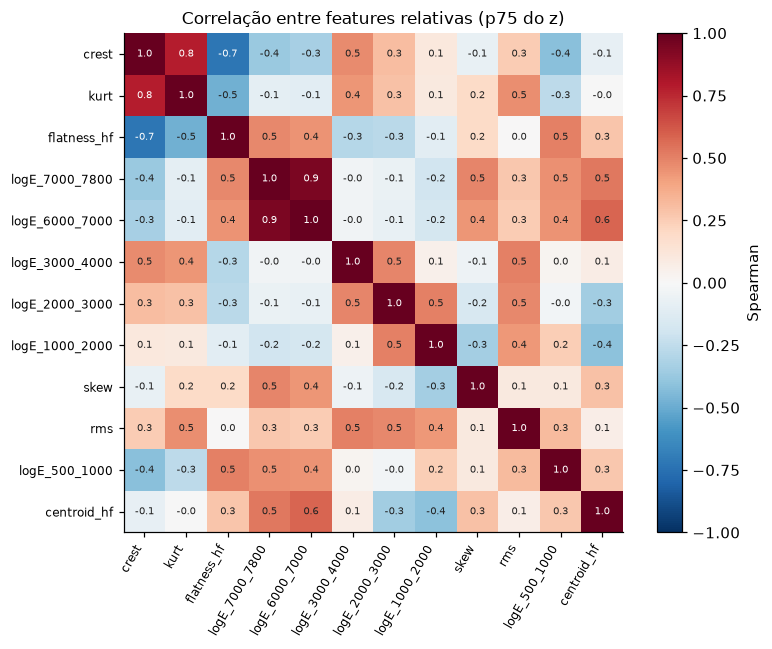

In [37]:
# Correlação entre features relativas (asset-level) — redundância
corr = P_z75.loc[lab_idx, top + [f for f in tab.index[6:12]]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "#222")
ax.grid(False); plt.colorbar(im, ax=ax, label="Spearman"); ax.set_title("Correlação entre features relativas (p75 do z)")
plt.tight_layout(); plt.show()

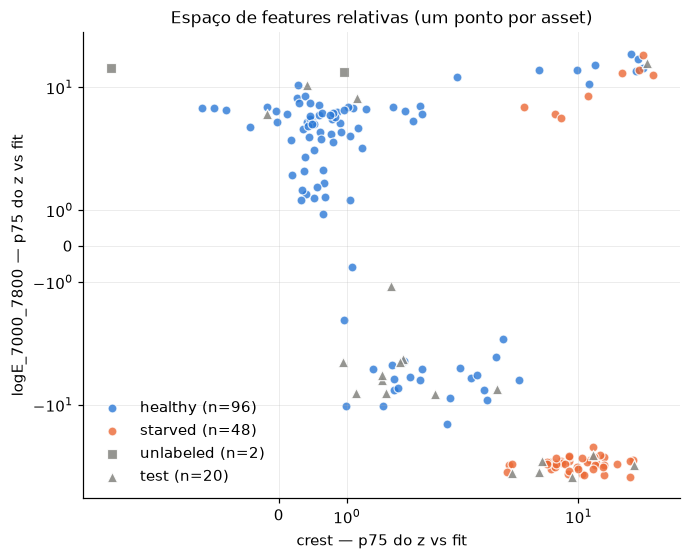

In [38]:
# Duas features relativas pouco correlacionadas entre as melhores
f1 = top[0]
f2 = next(f for f in tab.index[1:] if abs(corr.loc[f1, f]) < 0.6) if any(abs(corr.loc[f1, f]) < 0.6 for f in corr.columns) else top[1]
fig, ax = plt.subplots(figsize=(7, 5.5))
for lab in ["healthy", "starved", "unlabeled", "test"]:
    idx = meta.index[meta.label == lab]
    if len(idx) == 0: continue
    mk = dict(healthy="o", starved="o", unlabeled="s", test="^")[lab]
    ax.scatter(P_z75.loc[idx, f1], P_z75.loc[idx, f2], s=34 if lab in ("healthy", "starved") else 46,
               color=C[lab], marker=mk, alpha=0.8 if lab in ("healthy", "starved") else 0.9,
               edgecolors="white", linewidths=0.8, label=f"{lab} (n={len(idx)})")
ax.set_xscale("symlog", linthresh=3); ax.set_yscale("symlog", linthresh=3)
ax.set(xlabel=f"{f1} — p75 do z vs fit", ylabel=f"{f2} — p75 do z vs fit",
       title="Espaço de features relativas (um ponto por asset)")
ax.legend(); plt.show()

## 6. Granularidade: quantos sinais de um asset starved mostram o sintoma?

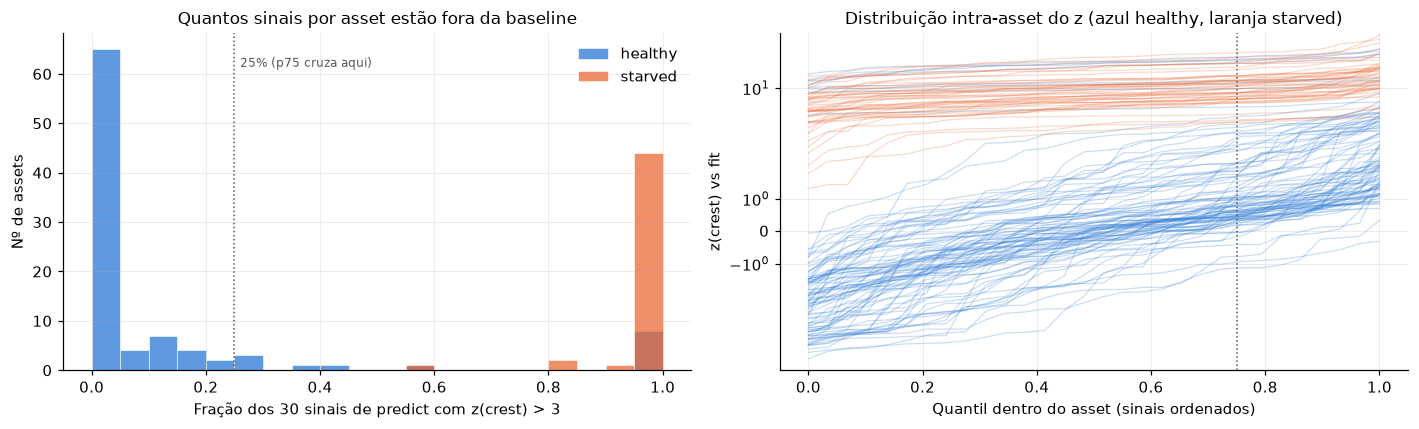

           count  mean   std   min   25%   50%   75%   max
label                                                     
healthy     96.0  0.13  0.28  0.00  0.00  0.00  0.10  1.00
starved     48.0  0.98  0.07  0.57  1.00  1.00  1.00  1.00
test        20.0  0.37  0.45  0.00  0.00  0.07  1.00  1.00
unlabeled    2.0  0.02  0.03  0.00  0.01  0.02  0.03  0.04


In [39]:
best = top[0]
sign = 1 if tab.loc[best, "AUC relativo (p75 z)"] >= 0.5 else -1
zb = Z[Z.set == "predict"].assign(s=lambda d: sign * d[best])
frac = zb.groupby("asset_id").s.apply(lambda v: np.mean(v > 3)).rename("frac_z_gt_3")
frac = meta.join(frac)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.linspace(0, 1, 21)
for lab in ["healthy", "starved"]:
    axes[0].hist(frac[frac.label == lab].frac_z_gt_3, bins=bins, color=C[lab], alpha=0.75,
                 label=lab, edgecolor="white", linewidth=0.5)
axes[0].axvline(0.25, color="#555", linestyle=":", linewidth=1)
axes[0].text(0.26, axes[0].get_ylim()[1] * 0.9, "25% (p75 cruza aqui)", fontsize=8, color="#555")
axes[0].set(xlabel=f"Fração dos 30 sinais de predict com z({best}) > 3", ylabel="Nº de assets",
            title="Quantos sinais por asset estão fora da baseline")
axes[0].legend()

# z por sinal, ordenado dentro de cada asset — curvas por classe
for lab in ["healthy", "starved"]:
    for aid in meta.index[meta.label == lab]:
        v = np.sort(zb[zb.asset_id == aid].s.values)
        axes[1].plot(np.linspace(0, 1, len(v)), v, color=C[lab], alpha=0.25, linewidth=0.8)
axes[1].axvline(0.75, color="#555", linestyle=":", linewidth=1)
axes[1].set_yscale("symlog", linthresh=3)
axes[1].set(xlabel="Quantil dentro do asset (sinais ordenados)", ylabel=f"z({best}) vs fit",
            title="Distribuição intra-asset do z (azul healthy, laranja starved)")
plt.tight_layout(); plt.show()
print(frac.groupby("label").frac_z_gt_3.describe().round(2))

## 7. Estabilidade da baseline: healthy deriva entre fit e predict?

In [40]:
# Para assets healthy, o z do predict deveria ficar em torno de 0. Quanto ele espalha?
hz = Z[(Z.set == "predict") & (Z.label == "healthy")][top]
fz = Z[(Z.set == "fit") & (Z.label == "healthy")][top]
summary = pd.DataFrame({
    "fit: |z|>3 (%)": (fz.abs() > 3).mean() * 100,
    "predict healthy: |z|>3 (%)": (hz.abs() > 3).mean() * 100,
    "predict healthy: mediana z": hz.median(),
}).round(2)
summary

,fit: |z|>3 (%),predict healthy: |z|>3 (%),predict healthy: mediana z
crest,1.84,16.46,0.34
kurt,0.19,11.98,0.23
flatness_hf,1.41,32.67,-0.55
logE_7000_7800,0.43,67.19,2.83
logE_6000_7000,0.28,69.34,3.17
logE_3000_4000,0.26,74.03,4.37


## 8. Dados de teste vs treino

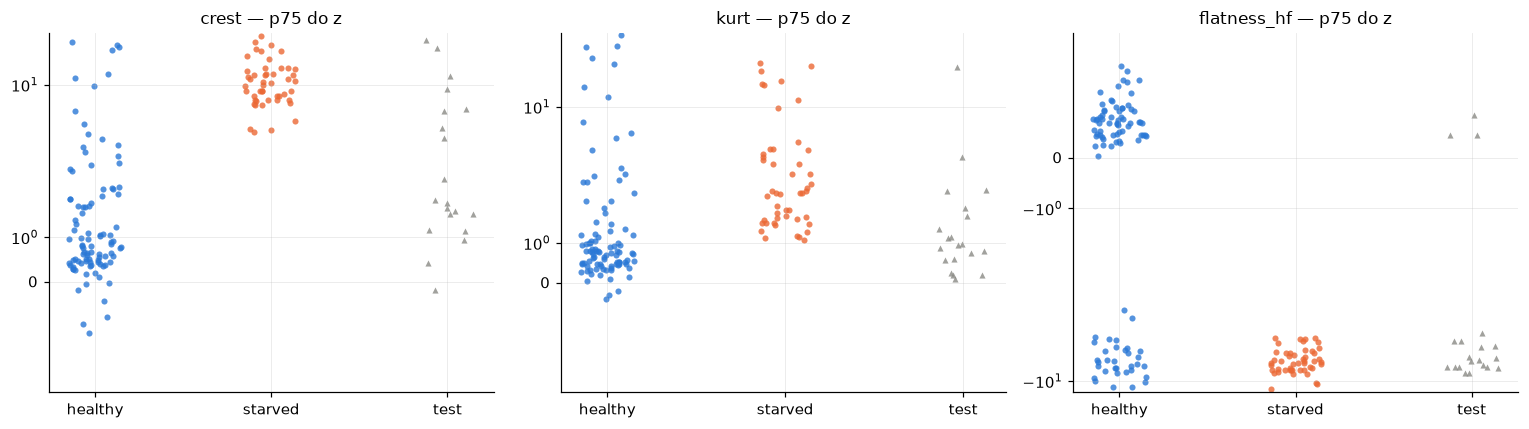

label                   healthy   starved      test  unlabeled
rms            min        0.391     0.392     0.398      0.754
               median     1.793     1.812     1.800      0.758
               max        3.162     3.140     3.146      0.761
logE_1000_2000 min       -4.175    -3.768    -3.884     -3.586
               median    -2.439    -2.339    -2.397     -2.954
               max        0.480     0.457     0.447     -2.323
logE_4000_5000 min       -4.006    -3.791    -3.909     -1.386
               median    -2.440    -2.379    -2.437     -0.931
               max       -1.265    -1.841    -1.877     -0.477
centroid_hf    min     1280.499  1301.226  1300.532   4584.599
               median  4383.532  4394.850  4384.876   4624.670
               max     4906.869  4435.010  4426.721   4664.740

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, f in zip(axes, top[:3]):
    for k, lab in enumerate(["healthy", "starved", "test"]):
        v = P_z75.loc[meta.index[meta.label == lab], f].values
        ax.scatter(np.full(len(v), k) + rng.uniform(-0.15, 0.15, len(v)), v, s=16, color=C[lab],
                   marker="^" if lab == "test" else "o", alpha=0.8, linewidths=0)
    ax.set_xticks([0, 1, 2]); ax.set_xticklabels(["healthy", "starved", "test"])
    ax.set_yscale("symlog", linthresh=3); ax.set_title(f"{f} — p75 do z")
plt.tight_layout(); plt.show()

# Shift absoluto: baseline (fit) do teste cabe na faixa do treino?
fit_abs = F[F.set == "fit"].groupby("asset_id")[["rms", "logE_1000_2000", "logE_4000_5000", "centroid_hf"]].median().join(meta)
fit_abs.drop(columns="split").groupby("label").agg(["min", "median", "max"]).T.round(3)

In [42]:
# Quantos assets de teste "parecem" starved pelas duas regras mais simples vistas acima
crest_abs = F[F.set == "predict"].groupby("asset_id").crest.median()
t = meta[meta.label == "test"].index
print("Teste — crest absoluto (mediana predict) > 3,2:", int((crest_abs[t] > 3.2).sum()), "de", len(t))
print("Teste — >50% dos sinais com z(crest) > 3:", int((frac.loc[t, "frac_z_gt_3"] > 0.5).sum()), "de", len(t))
for lab in ["healthy", "starved"]:
    i = meta.index[meta.label == lab]
    print(f"{lab:8s} — crest abs > 3,2: {(crest_abs[i] > 3.2).mean():.0%} | frac z>3 > 50%: {(frac.loc[i, 'frac_z_gt_3'] > 0.5).mean():.0%}")

Teste — crest absoluto (mediana predict) > 3,2: 7 de 20
Teste — >50% dos sinais com z(crest) > 3: 7 de 20
healthy  — crest abs > 3,2: 8% | frac z>3 > 50%: 9%
starved  — crest abs > 3,2: 100% | frac z>3 > 50%: 100%


## 8b. Checagem de atalho: o `fit` sozinho já entrega o rótulo?

Se features calculadas só nos sinais de referência separassem as classes, o modelo poderia aprender a "reconhecer o asset" em vez do sintoma.

In [43]:
F_fit = F[F.set == "fit"].groupby("asset_id")[FEATS].median()
leak = pd.Series({f: auc(F_fit.loc[lab_idx, f], yy) for f in FEATS})
leak_tab = pd.DataFrame({"AUC só com fit": leak, "|AUC−0,5|": (leak - 0.5).abs()}).sort_values("|AUC−0,5|", ascending=False)
leak_tab.round(3).head(8)

,AUC só com fit,"|AUC−0,5|"
flatness_hf,0.644,0.144
centroid_hf,0.616,0.116
logE_7000_7800,0.608,0.108
logE_6000_7000,0.597,0.097
entropy_hf,0.595,0.095
rms,0.575,0.075
logE_0_500,0.574,0.074
logE_5000_6000,0.570,0.070


In [44]:
# Dispersão da baseline entre assets: starved tem fit mais homogêneo que healthy?
disp = F_fit.loc[lab_idx, ["flatness_hf", "logE_7000_7800", "crest", "kurt"]].join(meta.label)
disp.groupby("label").agg(["median", "std"]).round(3)

flatness_hf        logE_7000_7800         crest          kurt       
             median    std         median    std median    std median    std
label                                                                       
healthy       0.178  0.076         -2.564  0.774  2.509  0.140  2.288  0.156
starved       0.181  0.054         -2.466  0.704  2.507  0.142  2.253  0.160

## 9. Conclusões

- Dados: 144 assets rotulados (96 healthy, 48 starved) e 20 de teste, sem NaN nem clipping. As pastas `assets/test …` não têm rótulo e são atípicas: ficam fora.
- Sintoma: nos starved, o bloco de energia em banda é mais forte e o sinal fica mais impulsivo. Melhores features: crest (AUC 0,93) e curtose (0,87).
- Relativo ao `fit` quase não ajuda: a baseline é igual entre as classes e os healthy também mudam muito → detecção de anomalia pura daria falsos alarmes.
- Granularidade: nos starved, ~98% dos sinais mostram o sintoma; a regra p75 não é gargalo.
- Erro residual: ~8 healthy com crest alto, indistinguíveis com as features atuais.
- Referência: regra *crest > 3,2* ≈ 94% in-sample. Usar features físicas (sem as que medem o chão do float16) e validar agrupando por asset.

## 10. Teste de modelos: Reg. logística (baseline), SVM, Random Forest e k-NN

- Treino: cada sinal do `predict` herda o rótulo do asset. Decisão: regra fixa do desafio (p75 > 0,75).
- Validação: `StratifiedGroupKFold` (5 folds) agrupado por asset, 3 repetições.
- Features: `rms`, `crest`, `kurt`, `skew`, absolutas e absolutas + relativas ao `fit`. Hiperparâmetros fixos.

In [45]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score

BASE_FEATS = ["rms", "crest", "kurt", "skew"]
FEAT_ABS = BASE_FEATS
FEAT_REL = [f + "_z" for f in FEAT_ABS]
FEATURE_SETS = {"absoluto": FEAT_ABS, "absoluto + relativo": FEAT_ABS + FEAT_REL}

D = pd.concat([F[["asset_id", "label", "set"] + FEAT_ABS],
               Z[FEAT_ABS].add_suffix("_z")], axis=1)
DL = D[(D.set == "predict") & D.label.isin(["healthy", "starved"])].reset_index(drop=True)
DT = D[(D.set == "predict") & (D.label == "test")].reset_index(drop=True)
y_sig = (DL.label == "starved").astype(int).values
groups = DL.asset_id.values
asset_y = DL.groupby("asset_id").label.first().eq("starved").astype(int)
print(f"Treino: {len(DL)} sinais de {DL.asset_id.nunique()} assets | Teste: {len(DT)} sinais de {DT.asset_id.nunique()} assets")


class CrestRule:
    # Referência: limiar único no crest, escolhido no fold de treino (maximiza acurácia balanceada por sinal)
    def __init__(self, col):
        self.col = col
    def fit(self, X, y):
        x = X[:, self.col]
        cands = np.quantile(x, np.linspace(0.01, 0.99, 197))
        ba = [0.5 * (np.mean(x[y == 1] > c) + np.mean(x[y == 0] <= c)) for c in cands]
        self.thr_ = cands[int(np.argmax(ba))]
        return self
    def predict_proba(self, X):
        p = (X[:, self.col] > self.thr_).astype(float)
        return np.c_[1 - p, p]


def make_models(seed, cols):
    return {
        "Regra crest (ref.)": CrestRule(cols.index("crest")),
        "Reg. logística (baseline)": make_pipeline(
            StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)),
        # SVM não gera probabilidade: calibração de Platt (sigmoide) com CV interna de 5 folds
        "SVM (RBF)": make_pipeline(StandardScaler(), CalibratedClassifierCV(
            SVC(C=1.0, gamma="scale", class_weight="balanced"), method="sigmoid", cv=5, ensemble=False)),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, max_depth=4, min_samples_leaf=20, class_weight="balanced", n_jobs=-1, random_state=seed),
        # k=45: com 30 sinais por asset, garante vizinhos de pelo menos 2 assets diferentes
        "k-NN (k=45)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=45)),
    }

MODEL_NAMES = list(make_models(0, FEAT_ABS))

Treino: 4320 sinais de 144 assets | Teste: 600 sinais de 20 assets


In [46]:
def p75(v):
    return np.percentile(v, 75)

def cross_validate(cols, n_repeats=3, n_splits=5):
    X = DL[cols].values
    out = []
    for rep in range(n_repeats):
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=rep)
        for fold, (tr, te) in enumerate(cv.split(X, y_sig, groups)):
            for name, mdl in make_models(rep, cols).items():
                mdl.fit(X[tr], y_sig[tr])
                s = mdl.predict_proba(X[te])[:, 1]
                agg = pd.DataFrame({"asset_id": groups[te], "s": s}).groupby("asset_id").s.agg(p75=p75, med="median")
                out.append(agg.reset_index().assign(model=name, rep=rep, fold=fold))
    A = pd.concat(out, ignore_index=True)
    A["y"] = A.asset_id.map(asset_y)
    A["pred"] = (A.p75 > 0.75).astype(int)          # regra fixa do desafio
    return A

def asset_metrics(g):
    tp = ((g.pred == 1) & (g.y == 1)).sum(); fn = ((g.pred == 0) & (g.y == 1)).sum()
    fp = ((g.pred == 1) & (g.y == 0)).sum(); tn = ((g.pred == 0) & (g.y == 0)).sum()
    rec, spec = tp / (tp + fn), tn / (tn + fp)
    prec = tp / (tp + fp) if tp + fp else np.nan
    return pd.Series({"acurácia": (tp + tn) / len(g), "acurácia balanceada": (rec + spec) / 2,
                      "recall starved": rec, "falso alarme (healthy)": fp / (fp + tn),
                      "precisão starved": prec, "F1 starved": 2 * prec * rec / (prec + rec) if prec + rec else 0,
                      "AUC do p75": roc_auc_score(g.y, g.p75), "FP": fp, "FN": fn})

RESULTS = {}
for fs_name, cols in FEATURE_SETS.items():
    RESULTS[fs_name] = cross_validate(cols)

def summary_table(A):
    m = A.groupby(["model", "rep"]).apply(asset_metrics).groupby("model")
    mean, std = m.mean(), m.std()
    t = mean.copy().astype(object)
    for c in mean.columns:
        if c in ("FP", "FN"):
            t[c] = mean[c].map("{:.1f}".format)
        else:
            t[c] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(mean[c], std[c])]
    return t.loc[MODEL_NAMES]

for fs_name, A in RESULTS.items():
    print(f"\n=== Conjunto de features: {fs_name} — média ± desvio em 3 repetições de 5-fold agrupado (144 assets) ===")
    display(summary_table(A))


=== Conjunto de features: absoluto — média ± desvio em 3 repetições de 5-fold agrupado (144 assets) ===


,acurácia,acurácia balanceada,recall starved,falso alarme (healthy),precisão starved,F1 starved,AUC do p75,FP,FN
model,,,,,,,,,
Regra crest (ref.),0.944 ± 0.000,0.958 ± 0.000,1.000 ± 0.000,0.083 ± 0.000,0.857 ± 0.000,0.923 ± 0.000,0.958 ± 0.000,8.0,0.0
Reg. logística (baseline),0.975 ± 0.004,0.981 ± 0.003,1.000 ± 0.000,0.038 ± 0.006,0.929 ± 0.010,0.963 ± 0.006,0.992 ± 0.004,3.7,0.0
SVM (RBF),0.991 ± 0.004,0.993 ± 0.003,1.000 ± 0.000,0.014 ± 0.006,0.973 ± 0.011,0.986 ± 0.006,1.000 ± 0.000,1.3,0.0
Random Forest,0.981 ± 0.004,0.986 ± 0.003,1.000 ± 0.000,0.028 ± 0.006,0.947 ± 0.011,0.973 ± 0.006,0.999 ± 0.001,2.7,0.0
k-NN (k=45),0.977 ± 0.004,0.983 ± 0.003,1.000 ± 0.000,0.035 ± 0.006,0.935 ± 0.010,0.966 ± 0.006,0.988 ± 0.003,3.3,0.0



=== Conjunto de features: absoluto + relativo — média ± desvio em 3 repetições de 5-fold agrupado (144 assets) ===


,acurácia,acurácia balanceada,recall starved,falso alarme (healthy),precisão starved,F1 starved,AUC do p75,FP,FN
model,,,,,,,,,
Regra crest (ref.),0.944 ± 0.000,0.958 ± 0.000,1.000 ± 0.000,0.083 ± 0.000,0.857 ± 0.000,0.923 ± 0.000,0.958 ± 0.000,8.0,0.0
Reg. logística (baseline),0.975 ± 0.008,0.981 ± 0.006,1.000 ± 0.000,0.038 ± 0.012,0.929 ± 0.021,0.963 ± 0.011,0.999 ± 0.000,3.7,0.0
SVM (RBF),0.988 ± 0.004,0.991 ± 0.003,1.000 ± 0.000,0.017 ± 0.006,0.967 ± 0.011,0.983 ± 0.006,1.000 ± 0.000,1.7,0.0
Random Forest,0.986 ± 0.007,0.990 ± 0.005,1.000 ± 0.000,0.021 ± 0.010,0.960 ± 0.019,0.980 ± 0.010,0.997 ± 0.003,2.0,0.0
k-NN (k=45),0.977 ± 0.004,0.983 ± 0.003,1.000 ± 0.000,0.035 ± 0.006,0.935 ± 0.010,0.966 ± 0.006,0.999 ± 0.000,3.3,0.0


Como ler: FP = healthy marcados como starved; FN = starved perdidos. AUC do p75 alta com acurácia baixa = score mal calibrado para a regra.

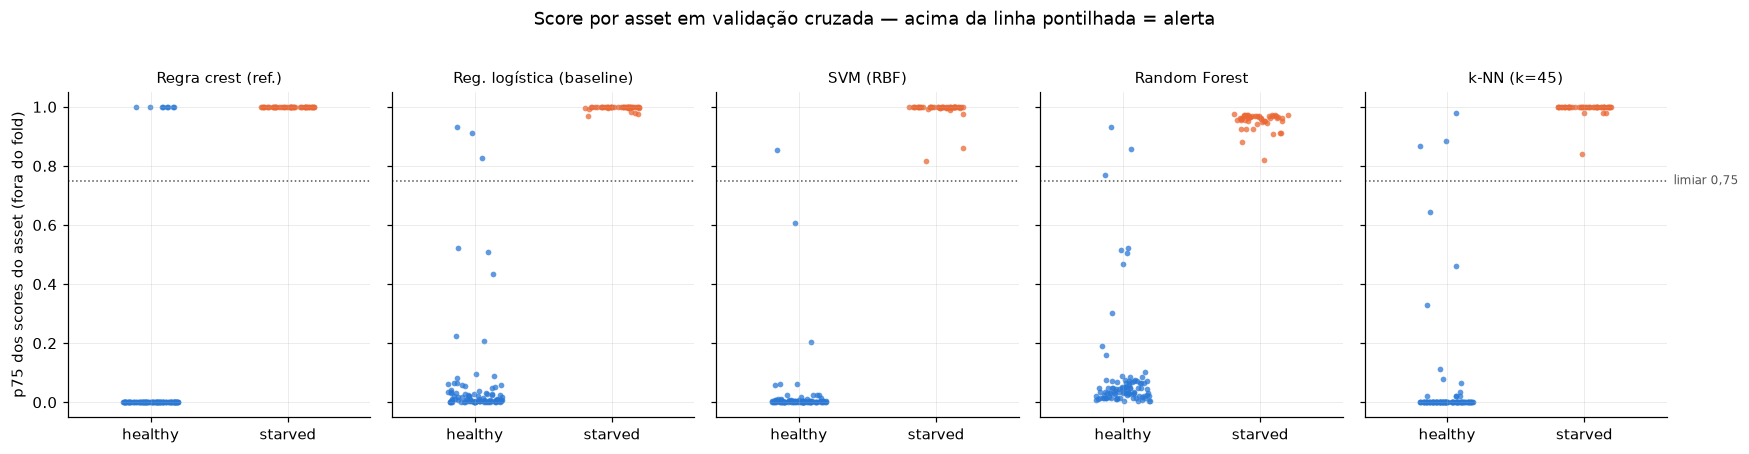

In [47]:
# Distribuição do score do asset (p75) por modelo — repetição 0, features absoluto + relativo
A0 = RESULTS["absoluto + relativo"].query("rep == 0")
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(16, 4), sharey=True)
rng = np.random.default_rng(0)
for ax, name in zip(axes, MODEL_NAMES):
    g = A0[A0.model == name]
    for k, lab in enumerate(["healthy", "starved"]):
        v = g[g.y == k].p75.values
        ax.scatter(k + rng.uniform(-0.2, 0.2, len(v)), v, s=14, color=C[lab], alpha=0.75, linewidths=0)
    ax.axhline(0.75, color="#555", linestyle=":", linewidth=1)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["healthy", "starved"]); ax.set_xlim(-0.6, 1.6)
    ax.set_title(name, fontsize=10)
axes[0].set_ylabel("p75 dos scores do asset (fora do fold)")
axes[-1].text(1.62, 0.75, " limiar 0,75", va="center", fontsize=8, color="#555")
plt.suptitle("Score por asset em validação cruzada — acima da linha pontilhada = alerta", y=1.02)
plt.tight_layout(); plt.show()

### 10.1 Onde os modelos erram

In [48]:
# Taxa de erro por asset (fração das 3 repetições em que o asset foi classificado errado), conjunto absoluto + relativo
A = RESULTS["absoluto + relativo"]
err = (A.assign(erro=(A.pred != A.y)).pivot_table(index="asset_id", columns="model", values="erro", aggfunc="mean")
       [MODEL_NAMES])
err = err[(err > 0).any(axis=1)]
err.insert(0, "rótulo", meta.loc[err.index, "label"])
err.insert(1, "crest abs (mediana)", crest_abs.loc[err.index].round(2))
err.insert(2, "crest abs > 3,2", crest_abs.loc[err.index] > 3.2)
print(f"{len(err)} assets erraram em pelo menos uma repetição de algum modelo "
      f"({(err['rótulo'] == 'healthy').sum()} healthy, {(err['rótulo'] == 'starved').sum()} starved)")
err.sort_values(["rótulo", "crest abs (mediana)"], ascending=[True, False]).round(2)

8 assets erraram em pelo menos uma repetição de algum modelo (8 healthy, 0 starved)


model,rótulo,crest abs (mediana),"crest abs > 3,2",Regra crest (ref.),Reg. logística (baseline),SVM (RBF),Random Forest,k-NN (k=45)
asset_id,,,,,,,,
a444f035-5e3d-4b80-b80e-864b6427924c,healthy,4.40,True,1.0,0.00,0.00,0.00,0.00
74091ba5-b7cc-457b-9444-551dd97e976f,healthy,4.39,True,1.0,0.00,0.00,0.00,0.00
fea05515-a0c2-416d-9336-c8bcc7de5404,healthy,4.39,True,1.0,1.00,0.00,0.00,0.33
a3be95dc-9e30-446f-aaab-0c6e14ba5a9f,healthy,4.25,True,1.0,0.67,0.00,0.00,0.00
80bfa1e6-7919-4175-91a3-0ac6150bbbb6,healthy,4.21,True,1.0,1.00,0.67,0.33,1.00
2f77b7d6-04f9-4796-9048-14b5b524383b,healthy,4.19,True,1.0,0.00,0.00,0.00,0.00
2af1e1d4-8628-4d62-834a-33b5c5cfc59e,healthy,3.79,True,1.0,0.67,0.67,0.67,1.00
3b8895fc-f18d-439d-8994-e758c96be47a,healthy,3.45,True,1.0,0.33,0.33,1.00,1.00


### 10.2 O que os modelos usam (ajustados em todos os 144 assets)

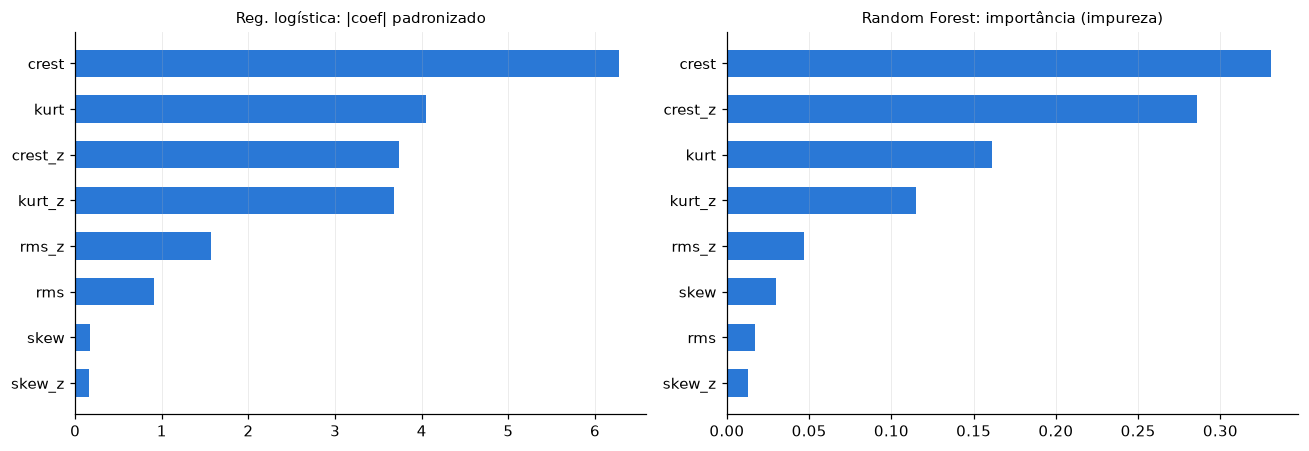

Sinal dos coeficientes da Reg. logística (+ = empurra para starved):
kurt      -4.05
kurt_z    -3.68
rms       -0.91
skew      -0.18
skew_z     0.16
rms_z      1.57
crest_z    3.74
crest      6.28


In [49]:
cols = FEATURE_SETS["absoluto + relativo"]
X_all = DL[cols].values
lr = make_models(0, cols)["Reg. logística (baseline)"].fit(X_all, y_sig)
rf = make_models(0, cols)["Random Forest"].fit(X_all, y_sig)
imp = pd.DataFrame({"Reg. logística: |coef| padronizado": np.abs(lr[-1].coef_[0]),
                    "Random Forest: importância (impureza)": rf.feature_importances_}, index=cols)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, c in zip(axes, imp.columns):
    s = imp[c].sort_values()
    ax.barh(s.index, s.values, color="#2a78d6", height=0.6)
    ax.set_title(c, fontsize=10); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("Sinal dos coeficientes da Reg. logística (+ = empurra para starved):")
print(pd.Series(lr[-1].coef_[0], index=cols).round(2).sort_values().to_string())

### 10.3 Previsão nos 20 assets de teste (sem rótulo)

Modelos ajustados nos 144 assets e aplicados ao `test_data/`. Sem gabarito: só decisão e concordância.

In [50]:
cols = FEATURE_SETS["absoluto + relativo"]
test_scores = {}
for name, mdl in make_models(0, cols).items():
    mdl.fit(DL[cols].values, y_sig)
    s = mdl.predict_proba(DT[cols].values)[:, 1]
    test_scores[name] = pd.DataFrame({"asset_id": DT.asset_id, "s": s}).groupby("asset_id").s.agg(p75)

TS = pd.DataFrame(test_scores)[MODEL_NAMES]
TD = (TS > 0.75)
summary = TS.round(2).astype(str) + np.where(TD, " - starved", "")
summary["nº de modelos que alertam"] = TD.sum(axis=1)
summary["crest abs (mediana)"] = crest_abs.loc[TS.index].round(2)
summary.index = [a[:8] for a in summary.index]
print("Assets de teste marcados como starved por modelo:", TD.sum().to_dict())
summary.sort_values("nº de modelos que alertam", ascending=False)

Assets de teste marcados como starved por modelo: {'Regra crest (ref.)': 7, 'Reg. logística (baseline)': 7, 'SVM (RBF)': 7, 'Random Forest': 7, 'k-NN (k=45)': 7}


,Regra crest (ref.),Reg. logística (baseline),SVM (RBF),Random Forest,k-NN (k=45),nº de modelos que alertam,crest abs (mediana)
698c671e,1.0 - starved,1.0 - starved,1.0 - starved,0.94 - starved,0.99 - starved,5,3.81
7bc09894,1.0 - starved,1.0 - starved,1.0 - starved,0.96 - starved,1.0 - starved,5,3.96
649b99cf,1.0 - starved,1.0 - starved,1.0 - starved,0.96 - starved,1.0 - starved,5,3.79
4edf71bf,1.0 - starved,0.91 - starved,1.0 - starved,0.96 - starved,1.0 - starved,5,3.44
e66af937,1.0 - starved,1.0 - starved,1.0 - starved,0.96 - starved,1.0 - starved,5,3.30
ed9f0130,1.0 - starved,1.0 - starved,1.0 - starved,0.96 - starved,1.0 - starved,5,3.86
b425a6af,1.0 - starved,0.98 - starved,1.0 - starved,0.94 - starved,1.0 - starved,5,3.49
04935ce5,0.0,0.01,0.0,0.01,0.0,0,2.65
38725ef2,0.0,0.1,0.0,0.02,0.0,0,2.78
35873e36,0.0,0.02,0.0,0.04,0.0,0,2.78


## 11. Conclusões dos modelos

| Modelo | Acurácia (CV) | Falsos alarmes | Starved perdidos |
|---|---|---|---|
| Regra crest (ref.) | 0,944 | 8 | 0 |
| Reg. logística (baseline) | 0,975 | 3,7 | 0 |
| k-NN (k=45) | 0,977 | 3,3 | 0 |
| Random Forest | 0,981–0,986 | 2,0–2,7 | 0 |
| SVM (RBF) | 0,988–0,991 | 1,3–1,7 | 0 |

- Todos superam a regra e têm recall de 100%; os erros são sempre os mesmos healthy de crest alto.
- As diferenças entre modelos são de 1 a 2 assets: empate estatístico. Features relativas ao `fit` ajudam pouco.
- Teste: todos concordam — 7 starved e 13 healthy.

Decisão: `LubricationModel` com SVM calibrado sobre as 4 features absolutas (`rms`, `crest`, `kurt`, `skew`).